# 04 · Model experiments (leak-free)

Features: the notebook-03 winner, promoted to `src/features.py` (`FeatureBuilder`): leak-free cleaning + the selected
null handling / features. Same 80/20 holdout as notebooks 02–03; every experiment = **3 seeds × 5-fold CV** on dev,
Platt-calibrated on OOF, reported as mean ± std. A **confusion matrix** is plotted for every experiment
(holdout, threshold = F1-optimal on that experiment's own OOF predictions, so the holdout never picks the threshold).

| § | Question | Why ask it |
|---|---|---|
| 1 | How strongly should the loss be weighted? | The textbook weight (#legit/#mule = 49) overfit in notebook 02. |
| 2 | Does **SMOTE** / undersampling beat a weighted loss? | The other standard answer to imbalance. |
| 3 | How much does **Optuna** tuning buy? | Default hyper-parameters are rarely optimal. |
| 4 | Is **CatBoost** better? | Different boosting scheme + categorical encoding. |
| 5 | Does a **blend** help? | Two different models may make different errors. |
| 6 | Does **Isolation Forest** add signal? | Mules may simply be *unusual* accounts, a label-free signal. |
| 7 | What would the **leak** have added? Are other features leaky? | Quantifies the cost of doing the right thing. |
| 8 | Final choice, calibration, explanation, errors | |

**Selection rule** (as in notebook 03): a candidate *ties* with the best if its OOF log-loss gap is within the
seed-to-seed noise (larger of the two standard deviations); among tied candidates choose the simplest.
Log-loss is the target because the case study scores probability accuracy.

In [1]:
import sys; sys.path.insert(0, '..')
import json, warnings
from time import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import optuna, xgboost as xgb
from catboost import CatBoostClassifier, Pool
from imblearn.over_sampling import SMOTENC
from imblearn.under_sampling import RandomUnderSampler
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import precision_recall_curve, confusion_matrix, log_loss, average_precision_score, roc_auc_score
from src.data import DataLoader, TARGET
from src.features import FeatureBuilder, COUNTERS
from src.model import XGBCV, PlattCalibrator, evaluate

warnings.filterwarnings('ignore', category=optuna.exceptions.ExperimentalWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
BLUE, ORANGE, AQUA, YELLOW, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#8a8984'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'axes.titleweight': 'bold', 'axes.titlesize': 11})
pd.set_option('display.float_format', '{:.4f}'.format, 'display.width', 200)

train = DataLoader().load('train')
y = train[TARGET]
X = FeatureBuilder().fit_transform(train)
idx_dev, idx_hold = train_test_split(train.index, test_size=.2, stratify=y, random_state=42)   # same split as 02/03
y_dev, y_hold = y.loc[idx_dev], y.loc[idx_hold]
X_dev, X_hold = X.loc[idx_dev], X.loc[idx_hold]
RATIO = (y_dev == 0).sum() / (y_dev == 1).sum()
SEEDS = (0, 1, 2)
assert not set(COUNTERS) & set(X.columns), 'leaky counters must not be in the feature set'
print(f'{X.shape[1]} leak-free features | dev {len(idx_dev):,} ({y_dev.sum()} mules) | holdout {len(idx_hold):,} ({y_hold.sum()} mules) | #legit/#mule = {RATIO:.0f}')

156 leak-free features | dev 80,000 (1600 mules) | holdout 20,000 (400 mules) | #legit/#mule = 49


## 0. Harness

In [2]:
RESULTS, RUNS, MODELS = {}, {}, {}

def f1_threshold(y_true, p):
    pr, rc, thr = precision_recall_curve(y_true, p)
    return thr[np.argmax(2 * pr[:-1] * rc[:-1] / (pr[:-1] + rc[:-1] + 1e-12))]

def record(name, runs, secs=0.0):
    """runs = [(calibrated OOF preds, calibrated holdout preds) per seed] -> mean ± std metrics."""
    rows = pd.DataFrame([{**{f'oof_{k}': v for k, v in evaluate(y_dev, o).items()},
                          **{f'hold_{k}': v for k, v in evaluate(y_hold, h).items()}} for o, h in runs])
    RUNS[name] = runs
    RESULTS[name] = pd.concat([rows.mean(), rows.std().fillna(0).add_suffix('_std')])
    m = RESULTS[name]
    print(f'{name:<34} OOF PR-AUC {m.oof_pr_auc:.4f}±{m.oof_pr_auc_std:.4f}  log-loss {m.oof_log_loss:.5f}±{m.oof_log_loss_std:.5f}'
          f' | holdout PR-AUC {m.hold_pr_auc:.4f}  log-loss {m.hold_log_loss:.5f} | {secs:.0f}s')

def run(name, make_cv, Xd=X_dev, Xh=X_hold, seeds=SEEDS):
    """Fit make_cv(seed) on dev for each seed, Platt-calibrate on OOF, record metrics. Keeps the last CV model."""
    t, runs = time(), []
    for s in seeds:
        cv = make_cv(s).fit(Xd, y_dev)
        cal = PlattCalibrator().fit(cv.oof_, y_dev)
        runs.append((cal.predict(cv.oof_), cal.predict(cv.predict_proba(Xh))))
    MODELS[name] = cv
    record(name, runs, time() - t)
    return cv

def plot_confusions(names, ncols=4):
    nrows = -(-len(names) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 3.2 * nrows), squeeze=False)
    for ax, n in zip(axes.flat, names):
        oof, hold = RUNS[n][-1]
        t = f1_threshold(y_dev, oof)
        cm = confusion_matrix(y_hold, hold >= t)
        ax.imshow(cm, cmap='Blues', norm=plt.matplotlib.colors.LogNorm(vmin=1, vmax=len(y_hold))); ax.grid(False)
        for (i, j), v in np.ndenumerate(cm):
            ax.text(j, i, f'{v:,}', ha='center', va='center', fontsize=11, color='white' if v > 1000 else 'black')
        tn, fp, fn, tp = cm.ravel()
        ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['pred legit', 'pred mule'], yticklabels=['legit', 'mule'])
        ax.set_title(f'{n}\nP={tp / max(tp + fp, 1):.3f} R={tp / (tp + fn):.3f} @t={t:.2f}', fontsize=9)
    for ax in axes.flat[len(names):]:
        ax.axis('off')
    plt.tight_layout(); plt.show()

def plot_curves(cv, title):
    """Weighted log-loss per round (train vs validation, 5 folds) + ROC-AUC when available."""
    has_auc = 'auc' in cv.curves_[0]['validation_1']
    fig, axes = plt.subplots(1, 1 + has_auc, figsize=(6.5 * (1 + has_auc), 4), squeeze=False)
    a1 = axes[0, 0]
    for k, (c, b) in enumerate(zip(cv.curves_, cv.best_iters_)):
        a1.plot(c['validation_0']['logloss'], color=BLUE, lw=1, alpha=.7, label='train' if k == 0 else None)
        a1.plot(c['validation_1']['logloss'], color=ORANGE, lw=1.5, alpha=.8, label='validation' if k == 0 else None)
        a1.scatter(b, c['validation_1']['logloss'][b], color=ORANGE, s=30, zorder=3, edgecolors='white')
        if has_auc:
            axes[0, 1].plot(c['validation_0']['auc'], color=BLUE, lw=1, alpha=.7, label='train' if k == 0 else None)
            axes[0, 1].plot(c['validation_1']['auc'], color=ORANGE, lw=1.5, alpha=.8, label='validation' if k == 0 else None)
    a1.set(title=f'{title}: weighted log-loss', xlabel='boosting round', yscale='log'); a1.legend()
    if has_auc:
        lo = min(min(c['validation_1']['auc'][10:]) for c in cv.curves_)
        axes[0, 1].set(title=f'{title}: ROC-AUC', xlabel='boosting round', ylim=(lo - .0005, 1.0002)); axes[0, 1].legend(loc='lower right')
    plt.tight_layout(); plt.show()

## 1. How strong should the class weight be?
**Why.** The weight is tied to the class distribution, **w = (#legit/#mule)^p**: p = 0 is no weighting, p = 0.5 is
√49 = 7, p = 1 is the textbook "balanced" 49. A larger weight makes every mule count more, so the model attends to the
rare class but each mule can be memorised (notebook 02: ×49 stopped improving after ~100 rounds). Sweep p with default
hyper-parameters to see the trade-off.

In [3]:
POWERS = [0, .25, .5, .75, 1]
SWEEP = [f'XGB p={p} (w={RATIO ** p:.1f})' for p in POWERS]
for p, name in zip(POWERS, SWEEP):
    run(name, lambda s, p=p: XGBCV(weight_power=p, seed=s))

XGB p=0 (w=1.0)                    OOF PR-AUC 0.9431±0.0033  log-loss 0.01381±0.00032 | holdout PR-AUC 0.9579  log-loss 0.01213 | 45s


XGB p=0.25 (w=2.6)                 OOF PR-AUC 0.9409±0.0011  log-loss 0.01400±0.00012 | holdout PR-AUC 0.9548  log-loss 0.01263 | 40s


XGB p=0.5 (w=7.0)                  OOF PR-AUC 0.9372±0.0006  log-loss 0.01445±0.00013 | holdout PR-AUC 0.9496  log-loss 0.01343 | 36s


XGB p=0.75 (w=18.5)                OOF PR-AUC 0.9332±0.0012  log-loss 0.01499±0.00013 | holdout PR-AUC 0.9445  log-loss 0.01408 | 34s


XGB p=1 (w=49.0)                   OOF PR-AUC 0.9270±0.0021  log-loss 0.01575±0.00027 | holdout PR-AUC 0.9395  log-loss 0.01476 | 34s


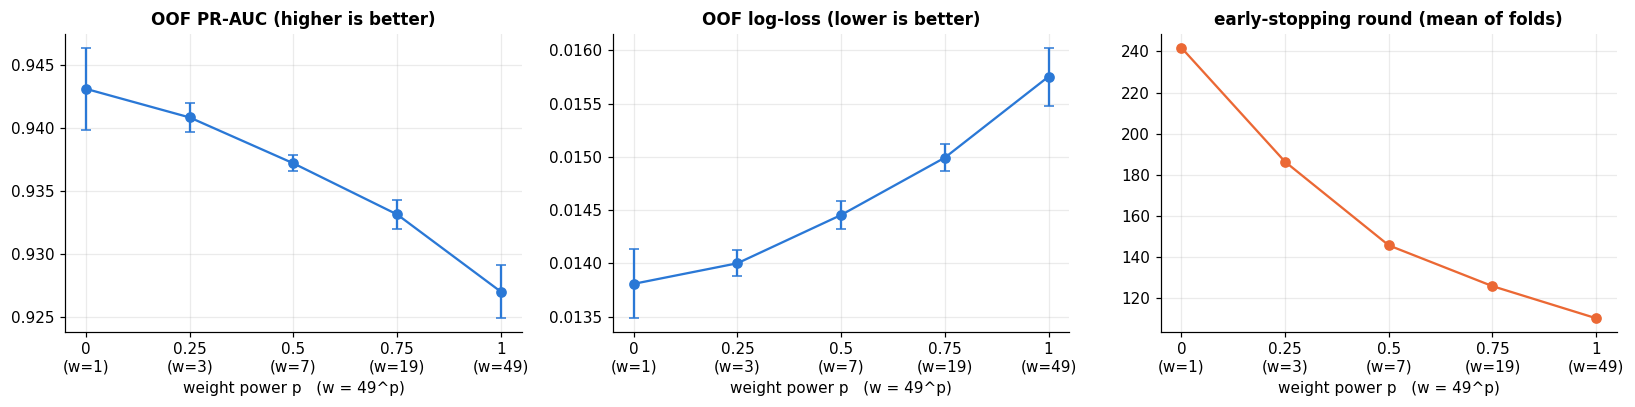

,oof_pr_auc,oof_pr_auc_std,oof_log_loss,oof_log_loss_std,hold_pr_auc,hold_log_loss
0.0000,0.9431,0.0033,0.0138,0.0003,0.9579,0.0121
0.2500,0.9409,0.0011,0.0140,0.0001,0.9548,0.0126
0.5000,0.9372,0.0006,0.0145,0.0001,0.9496,0.0134
0.7500,0.9332,0.0012,0.0150,0.0001,0.9445,0.0141
1.0000,0.9270,0.0021,0.0158,0.0003,0.9395,0.0148


In [4]:
sw = pd.DataFrame({p: RESULTS[n] for p, n in zip(POWERS, SWEEP)}).T
iters = [np.mean(MODELS[n].best_iters_) for n in SWEEP]
ticks = [f'{p}\n(w={RATIO ** p:.0f})' for p in POWERS]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, m, lab in zip(axes, ['oof_pr_auc', 'oof_log_loss'], ['OOF PR-AUC (higher is better)', 'OOF log-loss (lower is better)']):
    ax.errorbar(POWERS, sw[m], yerr=sw[f'{m}_std'], fmt='-o', color=BLUE, capsize=3, ms=6, lw=1.5)
    ax.set(xticks=POWERS, xlabel='weight power p   (w = 49^p)', title=lab); ax.set_xticklabels(ticks)
axes[2].plot(POWERS, iters, '-o', color=ORANGE, ms=6, lw=1.5)
axes[2].set(xticks=POWERS, xlabel='weight power p   (w = 49^p)', title='early-stopping round (mean of folds)'); axes[2].set_xticklabels(ticks)
plt.tight_layout(); plt.show()
sw[['oof_pr_auc', 'oof_pr_auc_std', 'oof_log_loss', 'oof_log_loss_std', 'hold_pr_auc', 'hold_log_loss']]

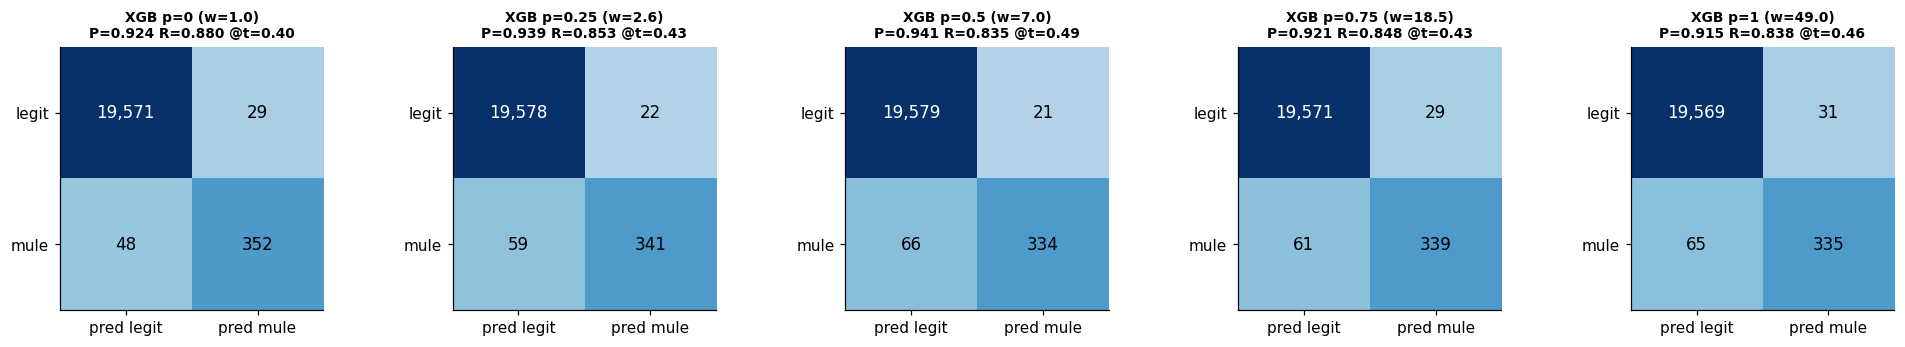

In [5]:
plot_confusions(SWEEP, ncols=5)

## 2. Resampling instead of weighting: SMOTE and undersampling
**Why.** Weighting changes how much each mule counts; resampling changes how many mules there are.
* **SMOTE-NC** (SMOTE for mixed numeric + categorical data) creates synthetic mules by interpolating between a mule and
  one of its 5 nearest mule neighbours. Applied **only to the training part of each fold**. Validation folds and the
  holdout keep the true 2% rate (oversampling before splitting would put near-copies of validation mules into training).
* **Random undersampling** keeps all mules and a random 10:1 subset of legit accounts (cheap, but discards data).
* SMOTE needs complete data, so all four runs here use median / most-frequent imputation and **no** class weight;
  the first run (imputed, no resampling) isolates the effect of resampling itself.

In [6]:
num_cols, cat_cols = X.select_dtypes('number').columns, X.select_dtypes('category').columns
X_imp = X.copy()
X_imp[num_cols] = X_imp[num_cols].fillna(X_dev[num_cols].median())
for c in cat_cols:
    X_imp[c] = X_imp[c].fillna(X_dev[c].mode()[0])
Xi_dev, Xi_hold = X_imp.loc[idx_dev], X_imp.loc[idx_hold]

def smote(ratio, seed):
    return lambda Xt, yt: SMOTENC(categorical_features='auto', sampling_strategy=ratio, random_state=seed).fit_resample(Xt, yt)

def undersample(ratio, seed):
    return lambda Xt, yt: RandomUnderSampler(sampling_strategy=ratio, random_state=seed).fit_resample(Xt, yt)

RESAMPLING = ['Imputed, no resampling', 'SMOTE → 10% mules', 'SMOTE → 50% mules', 'Undersample legit → 10:1']
run(RESAMPLING[0], lambda s: XGBCV(weight_power=0, seed=s), Xi_dev, Xi_hold)
run(RESAMPLING[1], lambda s: XGBCV(weight_power=0, seed=s, sampler=smote(.1, s)), Xi_dev, Xi_hold)
run(RESAMPLING[2], lambda s: XGBCV(weight_power=0, seed=s, sampler=smote(.5, s)), Xi_dev, Xi_hold)
run(RESAMPLING[3], lambda s: XGBCV(weight_power=0, seed=s, sampler=undersample(.1, s)), Xi_dev, Xi_hold)

Imputed, no resampling             OOF PR-AUC 0.9392±0.0018  log-loss 0.01450±0.00026 | holdout PR-AUC 0.9476  log-loss 0.01366 | 28s


SMOTE → 10% mules                  OOF PR-AUC 0.9399±0.0025  log-loss 0.01438±0.00028 | holdout PR-AUC 0.9448  log-loss 0.01414 | 78s


SMOTE → 50% mules                  OOF PR-AUC 0.9387±0.0007  log-loss 0.01457±0.00015 | holdout PR-AUC 0.9413  log-loss 0.01465 | 108s


Undersample legit → 10:1           OOF PR-AUC 0.9339±0.0018  log-loss 0.01501±0.00025 | holdout PR-AUC 0.9451  log-loss 0.01412 | 26s


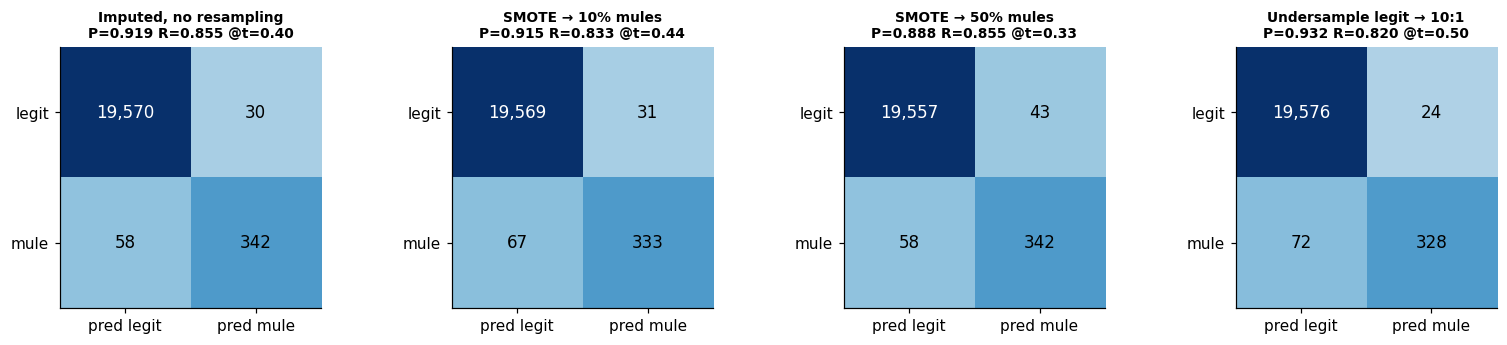

In [7]:
plot_confusions(RESAMPLING)

## 3. Optuna hyper-parameter tuning (XGBoost, GPU)
**Why.** Notebook 02's curves show the defaults overfit quickly; regularisation and the class weight interact
(a heavier weight needs more regularisation), so they are tuned **jointly** rather than one at a time.
* **Objective:** OOF log-loss after Platt calibration (5-fold CV on dev, fixed split); the holdout is never seen.
* **Search space:** weight power p ∈ [0, 1] (w = 49^p) and XGBoost's learning rate, tree depth, `min_child_weight`
  (minimum evidence per leaf), row/column subsampling, L1/L2 penalties, `gamma` (minimum gain to split) and
  `max_delta_step` (caps each leaf's update; XGBoost recommends it for logistic loss under heavy imbalance).
  The number of trees is set by early stopping.
* **Sampler:** TPE (Bayesian), 60 trials or 30 min. Trial 0 = the defaults, as an anchor.

In [8]:
def objective(trial):
    params = dict(
        learning_rate=trial.suggest_float('learning_rate', .02, .2, log=True),
        max_depth=trial.suggest_int('max_depth', 3, 10),
        min_child_weight=trial.suggest_float('min_child_weight', 1, 100, log=True),
        subsample=trial.suggest_float('subsample', .5, 1.0),
        colsample_bytree=trial.suggest_float('colsample_bytree', .3, 1.0),
        reg_lambda=trial.suggest_float('reg_lambda', 1e-2, 100, log=True),
        reg_alpha=trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        gamma=trial.suggest_float('gamma', 0, 5),
        max_delta_step=trial.suggest_float('max_delta_step', 0, 10),
    )
    p = trial.suggest_float('weight_power', 0, 1)
    cv = XGBCV(params, weight_power=p, seed=0).fit(X_dev, y_dev)
    pc = PlattCalibrator().fit(cv.oof_, y_dev).predict(cv.oof_)
    trial.set_user_attr('pr_auc', average_precision_score(y_dev, pc))
    return log_loss(y_dev, pc)

t = time()
study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=42))
study.enqueue_trial({'learning_rate': .05, 'max_depth': 6, 'min_child_weight': 1, 'subsample': 1, 'colsample_bytree': 1,
                     'reg_lambda': 1, 'reg_alpha': 1e-3, 'gamma': 0, 'max_delta_step': 0, 'weight_power': 1})
study.optimize(objective, n_trials=60, timeout=1800)
print(f'{len(study.trials)} trials in {(time() - t) / 60:.1f} min | best OOF log-loss {study.best_value:.5f} '
      f'(defaults: {study.trials[0].value:.5f}) | best PR-AUC {study.best_trial.user_attrs["pr_auc"]:.4f}')
best = dict(study.best_params)
best_p = best.pop('weight_power')
print(f'best weight power p = {best_p:.3f} -> mule weight {RATIO ** best_p:.1f}')
print('best XGBoost params:', json.dumps(best, indent=1))

59 trials in 30.1 min | best OOF log-loss 0.01294 (defaults: 0.01563) | best PR-AUC 0.9484
best weight power p = 0.211 -> mule weight 2.3
best XGBoost params: {
 "learning_rate": 0.03070970764402742,
 "max_depth": 9,
 "min_child_weight": 4.673729717992407,
 "subsample": 0.5014632634259749,
 "colsample_bytree": 0.5678047066568557,
 "reg_lambda": 2.5011099971684687,
 "reg_alpha": 0.003836121557645492,
 "gamma": 1.7547796847695507,
 "max_delta_step": 0.6496984996673965
}


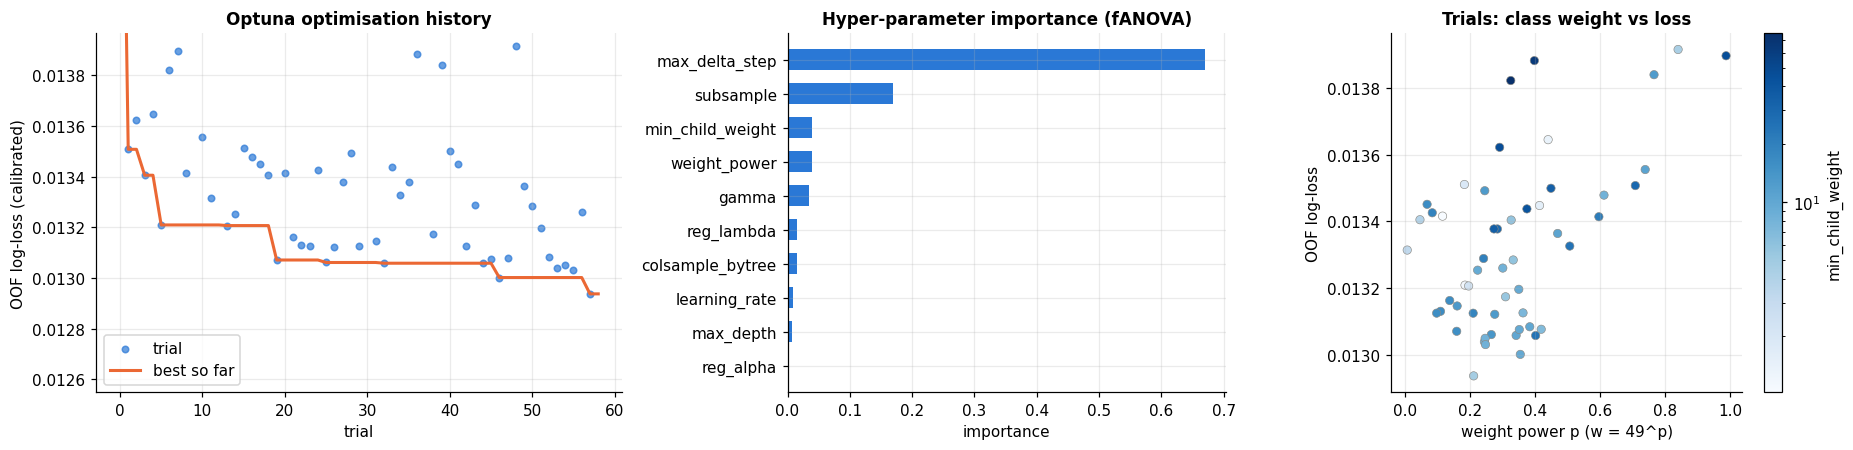

In [9]:
vals = study.trials_dataframe()
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), gridspec_kw={'width_ratios': [1.2, 1, 1]})
axes[0].scatter(vals.number, vals.value, s=18, color=BLUE, alpha=.7, label='trial')
axes[0].plot(vals.number, vals.value.cummin(), color=ORANGE, lw=2, label='best so far')
axes[0].set(xlabel='trial', ylabel='OOF log-loss (calibrated)', title='Optuna optimisation history',
            ylim=(vals.value.min() * .97, vals.value.quantile(.9))); axes[0].legend()
imp = optuna.importance.get_param_importances(study)
axes[1].barh(list(imp)[::-1], list(imp.values())[::-1], color=BLUE, height=.6)
axes[1].set(title='Hyper-parameter importance (fANOVA)', xlabel='importance')
ok = vals[vals.value < vals.value.quantile(.9)]
sc = axes[2].scatter(ok.params_weight_power, ok.value, c=ok.params_min_child_weight, cmap='Blues',
                     norm=plt.matplotlib.colors.LogNorm(), s=30, edgecolors=GRAY, lw=.4)
plt.colorbar(sc, ax=axes[2], label='min_child_weight')
axes[2].set(xlabel='weight power p (w = 49^p)', ylabel='OOF log-loss', title='Trials: class weight vs loss')
plt.tight_layout(); plt.show()

XGB tuned (Optuna)                 OOF PR-AUC 0.9489±0.0010  log-loss 0.01290±0.00008 | holdout PR-AUC 0.9532  log-loss 0.01251 | 84s


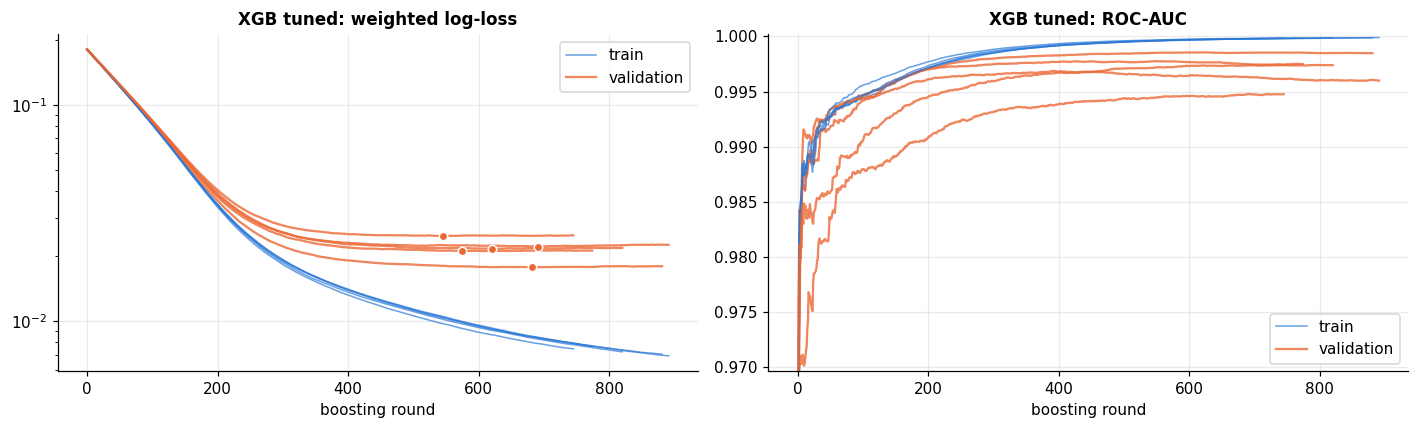

In [10]:
cv_tuned = run('XGB tuned (Optuna)', lambda s: XGBCV(best, weight_power=best_p, seed=s))
plot_curves(cv_tuned, 'XGB tuned')

## 4. CatBoost (GPU)
**Why.** CatBoost uses *ordered* boosting (each row's gradient is computed by a model that has not seen that row), which
reduces overfitting on small classes, and encodes categoricals with ordered target statistics. Same CV protocol and
the tuned class weight; CatBoost defaults otherwise (depth 6, lr 0.05, early stopping on weighted validation log-loss).
CatBoost needs categorical values as strings (missing → `"nan"`); numeric NaN is handled natively.

CatBoost                           OOF PR-AUC 0.9438±0.0006  log-loss 0.01373±0.00007 | holdout PR-AUC 0.9477  log-loss 0.01320 | 143s


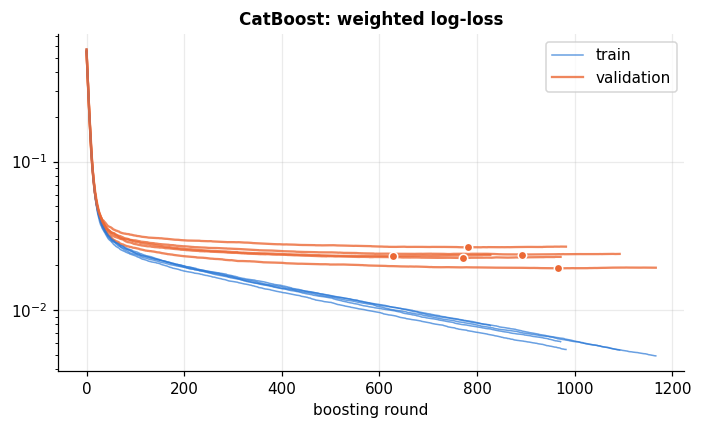

In [11]:
class CatCV:
    """Stratified K-fold CatBoost with a class-weighted log-loss (mirror of src.model.XGBCV)."""

    def __init__(self, weight_power, seed=0, n_splits=5, **params):
        self.weight_power, self.seed, self.n_splits = weight_power, seed, n_splits
        self.params = dict(iterations=5000, learning_rate=.05, depth=6, loss_function='Logloss', task_type='GPU',
                           early_stopping_rounds=200, random_seed=seed, verbose=0, allow_writing_files=False, **params)

    @staticmethod
    def _prep(X):
        X = X.copy()
        for c in X.select_dtypes('category').columns:
            X[c] = X[c].astype(str).fillna('nan')
        return X

    def fit(self, X, y):
        X, y = self._prep(X), np.asarray(y)
        self.cats_ = list(X.select_dtypes(exclude='number').columns)
        w = np.where(y == 1, ((y == 0).sum() / (y == 1).sum()) ** self.weight_power, 1.0)
        self.oof_, self.models_, self.curves_, self.best_iters_ = np.zeros(len(y)), [], [], []
        for tr, va in StratifiedKFold(self.n_splits, shuffle=True, random_state=self.seed).split(X, y):
            m = CatBoostClassifier(**self.params)
            m.fit(Pool(X.iloc[tr], y[tr], cat_features=self.cats_, weight=w[tr]),
                  eval_set=Pool(X.iloc[va], y[va], cat_features=self.cats_, weight=w[va]))
            self.oof_[va] = m.predict_proba(X.iloc[va])[:, 1]
            ev = m.get_evals_result()
            self.curves_.append({'validation_0': {'logloss': ev['learn']['Logloss']}, 'validation_1': {'logloss': ev['validation']['Logloss']}})
            self.models_.append(m); self.best_iters_.append(m.get_best_iteration())
        return self

    def predict_proba(self, X):
        X = self._prep(X)
        return np.mean([m.predict_proba(X)[:, 1] for m in self.models_], axis=0)

cv_cat = run('CatBoost', lambda s: CatCV(weight_power=best_p, seed=s))
plot_curves(cv_cat, 'CatBoost')

## 5. Blend: XGBoost (tuned) + CatBoost
**Why.** Averaging two models helps only if their errors differ; the correlation of their OOF predictions measures that.
The two calibrated probabilities are averaged in logit space and re-calibrated with Platt on the blended OOF.
Seeds are paired (seed *k* of XGBoost with seed *k* of CatBoost).

In [12]:
logit = lambda p: np.log(np.clip(p, 1e-7, 1 - 1e-7) / (1 - np.clip(p, 1e-7, 1 - 1e-7)))
sigmoid = lambda z: 1 / (1 + np.exp(-z))
blend_runs = []
for (xo, xh), (co, ch) in zip(RUNS['XGB tuned (Optuna)'], RUNS['CatBoost']):
    bo, bh = sigmoid((logit(xo) + logit(co)) / 2), sigmoid((logit(xh) + logit(ch)) / 2)
    cal = PlattCalibrator().fit(bo, y_dev)
    blend_runs.append((cal.predict(bo), cal.predict(bh)))
record('Blend XGB + CatBoost', blend_runs)
print(f"correlation of OOF logits, XGB vs CatBoost: {np.corrcoef(logit(RUNS['XGB tuned (Optuna)'][0][0]), logit(RUNS['CatBoost'][0][0]))[0, 1]:.3f}")

Blend XGB + CatBoost               OOF PR-AUC 0.9491±0.0002  log-loss 0.01287±0.00005 | holdout PR-AUC 0.9530  log-loss 0.01247 | 0s
correlation of OOF logits, XGB vs CatBoost: 0.913


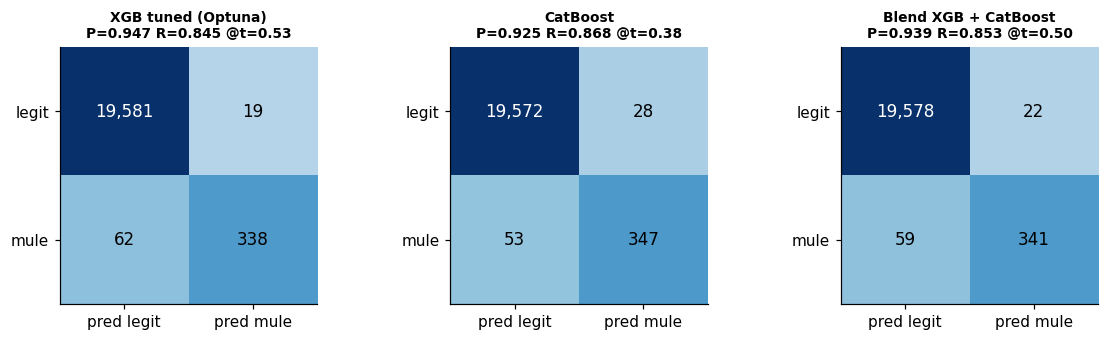

In [13]:
plot_confusions(['XGB tuned (Optuna)', 'CatBoost', 'Blend XGB + CatBoost'], ncols=3)

## 6. Isolation Forest
**Why.** An Isolation Forest scores how *unusual* an account is without using labels: it builds random trees and
measures how few random splits it takes to isolate a point (anomalies are isolated quickly). Two uses:
* **(a) Stand-alone detector**: how far does "unusual = mule" get with no labels at all?
* **(b) Extra feature**: does the anomaly score add anything the supervised model has not already learned?

It needs complete data, so it is fitted on the median-imputed features of **dev rows only** (label-free, so fitting
it on all dev rows does not leak labels into the CV folds). 300 trees, default sub-sample of 256 rows per tree.

Isolation Forest (unsupervised)    OOF PR-AUC 0.1203±0.0044  log-loss 0.08616±0.00035 | holdout PR-AUC 0.1495  log-loss 0.08421 | 0s


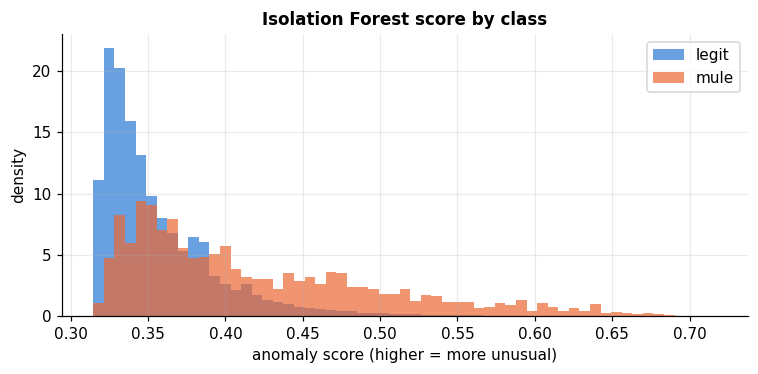

In [14]:
def iso_scores(seed):
    iso = IsolationForest(n_estimators=300, random_state=seed, n_jobs=-1).fit(X_imp.loc[idx_dev, num_cols])
    return pd.Series(-iso.score_samples(X_imp[num_cols]), index=X.index)   # higher = more anomalous, in (0, 1)

iso_runs, ISO = [], {}
for s in SEEDS:
    ISO[s] = iso_scores(s)
    cal = PlattCalibrator().fit(ISO[s].loc[idx_dev].values, y_dev)
    iso_runs.append((cal.predict(ISO[s].loc[idx_dev].values), cal.predict(ISO[s].loc[idx_hold].values)))
record('Isolation Forest (unsupervised)', iso_runs)

fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.linspace(ISO[0].min(), ISO[0].max(), 60)
ax.hist(ISO[0][y == 0], bins=bins, color=BLUE, alpha=.7, density=True, label='legit')
ax.hist(ISO[0][y == 1], bins=bins, color=ORANGE, alpha=.7, density=True, label='mule')
ax.set(xlabel='anomaly score (higher = more unusual)', ylabel='density', title='Isolation Forest score by class'); ax.legend()
plt.tight_layout(); plt.show()

XGB tuned + IF score feature       OOF PR-AUC 0.9489±0.0012  log-loss 0.01289±0.00009 | holdout PR-AUC 0.9532  log-loss 0.01253 | 87s


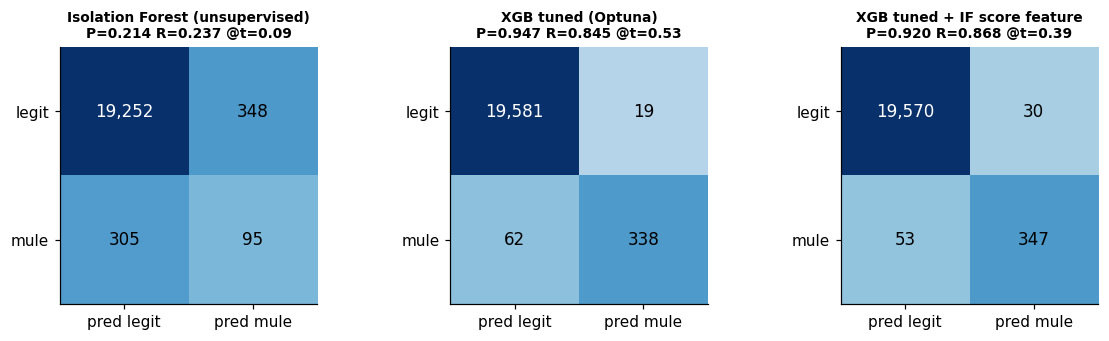

In [15]:
run('XGB tuned + IF score feature', lambda s: XGBCV(best, weight_power=best_p, seed=s),
    X_dev.assign(iso_score=ISO[0].loc[idx_dev]), X_hold.assign(iso_score=ISO[0].loc[idx_hold]))
plot_confusions(['Isolation Forest (unsupervised)', 'XGB tuned (Optuna)', 'XGB tuned + IF score feature'], ncols=3)

## 7. Leakage: what the counters would add, and are any other features leaky?
**(a) Audit.** If a feature changes because the bank *closed* the account, it will differ between closed and open
**legit** accounts (no mule effect involved). For every feature, ROC-AUC of "closed vs open" among legit accounts
(closed = `others_13` counter short of the account age): ≈ 0.5 means unaffected by closure, ≈ 1 means it encodes closure.

**(b) Cost of being leak-free.** Same tuned model with the 9 counters and their shortfall (`account_age − counter`) added back.

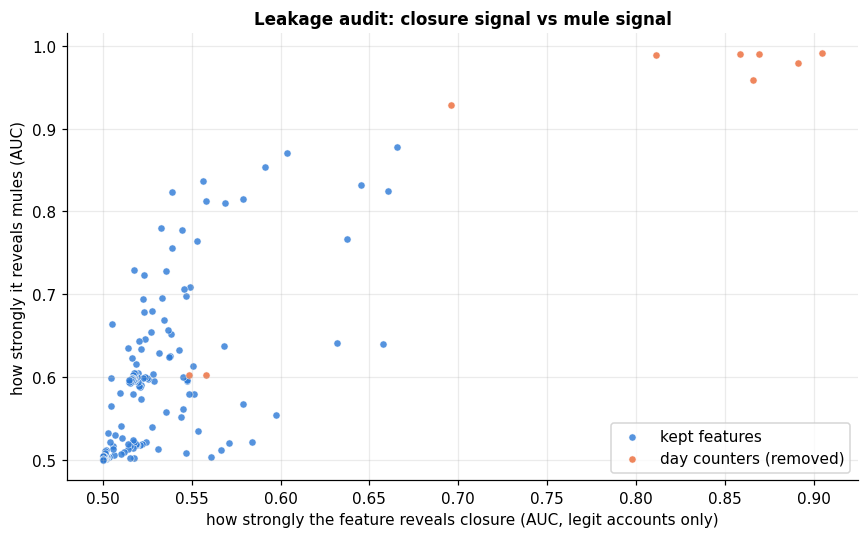

,closure_auc (legit only),mule_auc,counter
others_13,0.9048,0.9907,True
others_7,0.8915,0.9797,True
others_12,0.8693,0.9905,True
others_10,0.8660,0.9583,True
others_6,0.8589,0.9906,True
demog_23,0.8111,0.9892,True
others_9,0.6957,0.9287,True
others_25,0.6658,0.8776,False
others_21,0.6602,0.8251,False
others_17,0.6575,0.6397,False


In [16]:
closed = (X.account_age - train.others_13 > 0)
legit = (y == 0)
audit = {}
for c in list(X.columns) + COUNTERS:
    v = (X[c] if c in X else train[c])
    v = (v.cat.codes if isinstance(v.dtype, pd.CategoricalDtype) else v).astype(float).fillna(-999)
    if v[legit].nunique() > 1:
        a, m = roc_auc_score(closed[legit], v[legit]), roc_auc_score(y, v)
        audit[c] = {'closure_auc (legit only)': max(a, 1 - a), 'mule_auc': max(m, 1 - m), 'counter': c in COUNTERS}
audit = pd.DataFrame(audit).T.astype({'closure_auc (legit only)': float, 'mule_auc': float, 'counter': bool})
audit = audit.sort_values('closure_auc (legit only)', ascending=False)
fig, ax = plt.subplots(figsize=(8, 5))
for is_c, col, lab in [(False, BLUE, 'kept features'), (True, ORANGE, 'day counters (removed)')]:
    d = audit[audit.counter == is_c]
    ax.scatter(d['closure_auc (legit only)'], d['mule_auc'], s=22, color=col, label=lab, alpha=.8, edgecolors='white', lw=.4)
ax.set(xlabel='how strongly the feature reveals closure (AUC, legit accounts only)', ylabel='how strongly it reveals mules (AUC)',
       title='Leakage audit: closure signal vs mule signal'); ax.legend(loc='lower right')
plt.tight_layout(); plt.show()
audit.head(15)

Leaky: tuned XGB + counters        OOF PR-AUC 0.9764±0.0010  log-loss 0.00799±0.00011 | holdout PR-AUC 0.9761  log-loss 0.00862 | 81s


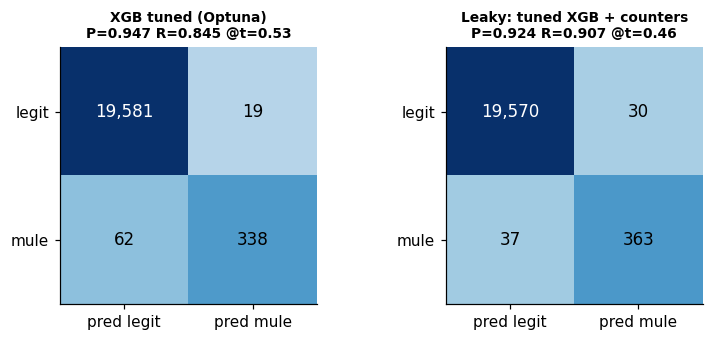

In [17]:
def add_counters(Xf, df):
    Xf = Xf.copy()
    for c in COUNTERS:
        Xf[c] = df[c]
        Xf[f'short_{c}'] = Xf.account_age - df[c]
    return Xf

X_leaky = add_counters(X, train)
run('Leaky: tuned XGB + counters', lambda s: XGBCV(best, weight_power=best_p, seed=s), X_leaky.loc[idx_dev], X_leaky.loc[idx_hold])
plot_confusions(['XGB tuned (Optuna)', 'Leaky: tuned XGB + counters'], ncols=2)

## 8. Final comparison

In [18]:
res = pd.DataFrame(RESULTS).T
cols = ['oof_pr_auc', 'oof_pr_auc_std', 'oof_log_loss', 'oof_log_loss_std', 'oof_brier', 'oof_roc_auc',
        'hold_pr_auc', 'hold_log_loss', 'hold_brier', 'hold_roc_auc']
res[cols].sort_values('oof_log_loss')

,oof_pr_auc,oof_pr_auc_std,oof_log_loss,oof_log_loss_std,oof_brier,oof_roc_auc,hold_pr_auc,hold_log_loss,hold_brier,hold_roc_auc
Leaky: tuned XGB + counters,0.9764,0.0010,0.0080,0.0001,0.0023,0.9994,0.9761,0.0086,0.0024,0.9994
Blend XGB + CatBoost,0.9491,0.0002,0.0129,0.0000,0.0032,0.9967,0.9530,0.0125,0.0032,0.9978
XGB tuned + IF score feature,0.9489,0.0012,0.0129,0.0001,0.0032,0.9967,0.9532,0.0125,0.0032,0.9975
XGB tuned (Optuna),0.9489,0.0010,0.0129,0.0001,0.0032,0.9967,0.9532,0.0125,0.0032,0.9975
CatBoost,0.9438,0.0006,0.0137,0.0001,0.0034,0.9961,0.9477,0.0132,0.0033,0.9977
XGB p=0 (w=1.0),0.9431,0.0033,0.0138,0.0003,0.0034,0.9962,0.9579,0.0121,0.0031,0.9975
XGB p=0.25 (w=2.6),0.9409,0.0011,0.0140,0.0001,0.0035,0.9959,0.9548,0.0126,0.0032,0.9969
SMOTE → 10% mules,0.9399,0.0025,0.0144,0.0003,0.0036,0.9959,0.9448,0.0141,0.0036,0.9962
XGB p=0.5 (w=7.0),0.9372,0.0006,0.0145,0.0001,0.0036,0.9959,0.9496,0.0134,0.0034,0.9960
"Imputed, no resampling",0.9392,0.0018,0.0145,0.0003,0.0036,0.9958,0.9476,0.0137,0.0035,0.9966


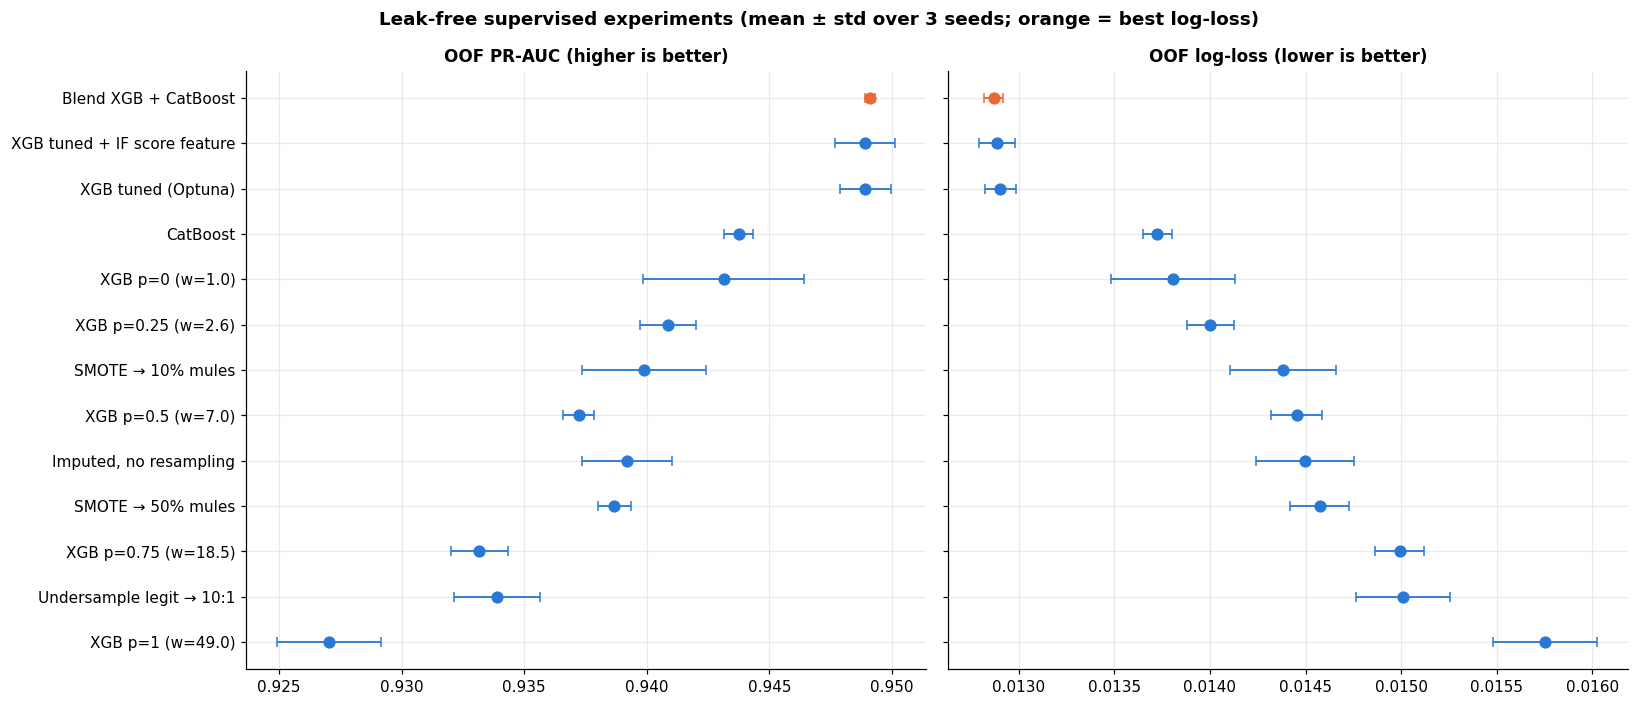

In [19]:
show = res.drop(index=['Leaky: tuned XGB + counters', 'Isolation Forest (unsupervised)']).sort_values('oof_log_loss', ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, m, lab in zip(axes, ['oof_pr_auc', 'oof_log_loss'], ['OOF PR-AUC (higher is better)', 'OOF log-loss (lower is better)']):
    for i, n in enumerate(show.index):
        ax.errorbar(show.loc[n, m], i, xerr=show.loc[n, f'{m}_std'], fmt='o', ms=7, capsize=3, lw=1.2,
                    color=ORANGE if n == show.index[-1] else BLUE)
    ax.set_yticks(range(len(show)), show.index if ax is axes[0] else [''] * len(show)); ax.set_title(lab)
plt.suptitle('Leak-free supervised experiments (mean ± std over 3 seeds; orange = best log-loss)', fontweight='bold')
plt.tight_layout(); plt.show()

In [20]:
# candidates ordered simplest-first; a candidate ties with the best if the gap is within the larger of their seed stds
CANDIDATES = ['XGB tuned (Optuna)', 'CatBoost', 'XGB tuned + IF score feature', 'Blend XGB + CatBoost']
best_c = min(CANDIDATES, key=lambda n: RESULTS[n].oof_log_loss)
tied = lambda a, b: a.oof_log_loss - b.oof_log_loss <= max(a.oof_log_loss_std, b.oof_log_loss_std)
WINNER = next(n for n in CANDIDATES if tied(RESULTS[n], RESULTS[best_c]))
print(f'best = {best_c}; simplest tied with it = {WINNER}')
res.loc[CANDIDATES, ['oof_log_loss', 'oof_log_loss_std', 'oof_pr_auc', 'hold_log_loss', 'hold_pr_auc']]

best = Blend XGB + CatBoost; simplest tied with it = XGB tuned (Optuna)


,oof_log_loss,oof_log_loss_std,oof_pr_auc,hold_log_loss,hold_pr_auc
XGB tuned (Optuna),0.0129,0.0001,0.9489,0.0125,0.9532
CatBoost,0.0137,0.0001,0.9438,0.0132,0.9477
XGB tuned + IF score feature,0.0129,0.0001,0.9489,0.0125,0.9532
Blend XGB + CatBoost,0.0129,0.0000,0.9491,0.0125,0.9530


### Winner: calibration, explanation and errors

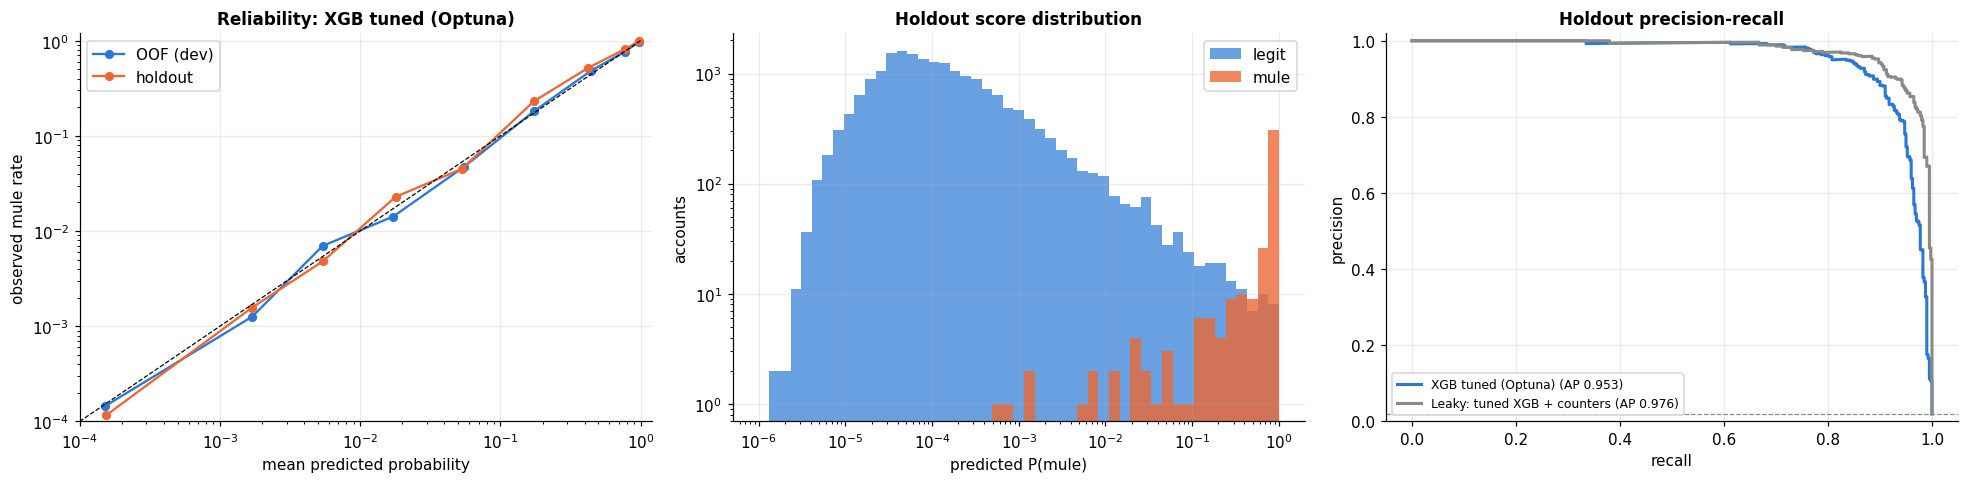

holdout: mean predicted 0.0192 vs actual 0.0200


In [21]:
oof_w, hold_w = RUNS[WINNER][-1]

def reliability(y_true, p, edges=(0, 1e-3, 3e-3, .01, .03, .1, .3, .6, .9, 1)):
    b = np.digitize(p, edges[1:-1])
    g = pd.DataFrame({'y': np.asarray(y_true), 'p': p, 'b': b}).groupby('b').agg(p=('p', 'mean'), y=('y', 'mean'), n=('y', 'size'))
    return g[g.n >= 20]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for (lab, yy, pp), col in zip([('OOF (dev)', y_dev, oof_w), ('holdout', y_hold, hold_w)], [BLUE, ORANGE]):
    r = reliability(yy, pp)
    axes[0].plot(r.p, r.y, marker='o', ms=5, lw=1.5, color=col, label=lab)
axes[0].plot([1e-4, 1], [1e-4, 1], ls='--', color='black', lw=.8)
axes[0].set(xscale='log', yscale='log', xlim=(1e-4, 1.2), ylim=(1e-4, 1.2), xlabel='mean predicted probability',
            ylabel='observed mule rate', title=f'Reliability: {WINNER}'); axes[0].legend()
bins = np.logspace(-6, 0, 50)
axes[1].hist(hold_w[y_hold == 0], bins=bins, color=BLUE, alpha=.7, label='legit')
axes[1].hist(hold_w[y_hold == 1], bins=bins, color=ORANGE, alpha=.8, label='mule')
axes[1].set(xscale='log', yscale='log', xlabel='predicted P(mule)', ylabel='accounts', title='Holdout score distribution'); axes[1].legend()
for n, col in [(WINNER, BLUE), ('Leaky: tuned XGB + counters', GRAY)]:
    pr, rc, _ = precision_recall_curve(y_hold, RUNS[n][-1][1])
    axes[2].plot(rc, pr, color=col, lw=2, label=f'{n} (AP {RESULTS[n].hold_pr_auc:.3f})')
axes[2].axhline(y_hold.mean(), color=GRAY, ls='--', lw=.8)
axes[2].set(xlabel='recall', ylabel='precision', ylim=(0, 1.02), title='Holdout precision-recall'); axes[2].legend(loc='lower left', fontsize=8)
plt.tight_layout(); plt.show()
print(f'holdout: mean predicted {hold_w.mean():.4f} vs actual {y_hold.mean():.4f}')

**SHAP values** of the tuned XGBoost: per-account, per-feature contributions to the log-odds (exact TreeSHAP, computed
natively by XGBoost with `pred_contribs=True`).

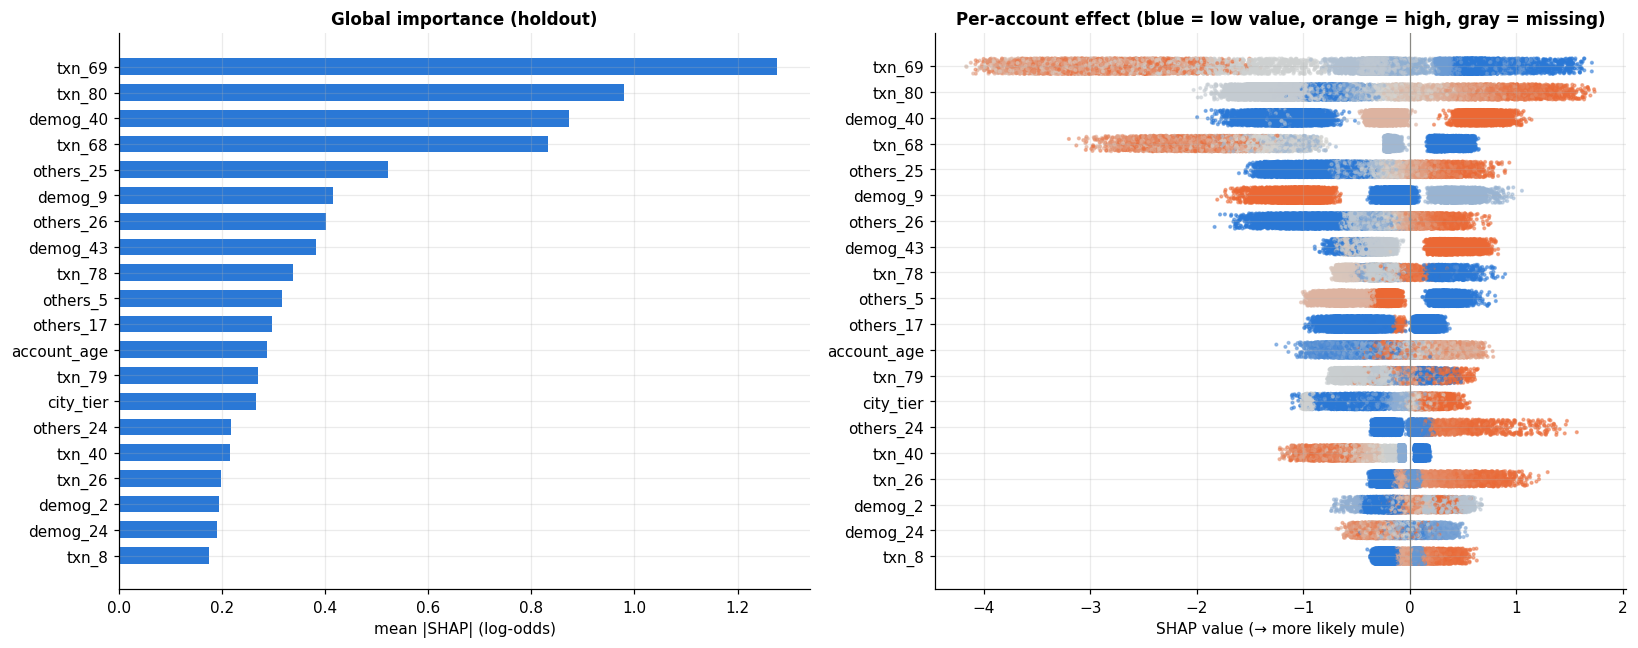

In [22]:
booster = cv_tuned.models_[0].get_booster()
contrib = booster.predict(xgb.DMatrix(X_hold, enable_categorical=True), pred_contribs=True)[:, :-1]
shap = pd.DataFrame(contrib, columns=X_hold.columns, index=X_hold.index)
mean_abs = shap.abs().mean().sort_values(ascending=False).head(20)[::-1]
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list('bo', [BLUE, '#d6d5d0', ORANGE])
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].barh(mean_abs.index, mean_abs.values, color=BLUE, height=.65)
axes[0].set(xlabel='mean |SHAP| (log-odds)', title='Global importance (holdout)')
rng = np.random.default_rng(0)
for i, c in enumerate(mean_abs.index):
    v = X_hold[c]
    v = v.cat.codes.replace(-1, np.nan) if isinstance(v.dtype, pd.CategoricalDtype) else v
    axes[1].scatter(shap[c], i + rng.uniform(-.3, .3, len(v)), c=v.rank(pct=True).fillna(.5), cmap=cmap, s=3, alpha=.5, rasterized=True)
axes[1].set_yticks(range(len(mean_abs)), mean_abs.index); axes[1].axvline(0, color=GRAY, lw=.8)
axes[1].set(xlabel='SHAP value (→ more likely mule)', title='Per-account effect (blue = low value, orange = high, gray = missing)')
plt.tight_layout(); plt.show()

**Error analysis.** What do caught mules, missed mules and false alarms look like? (holdout, F1-optimal threshold)

In [23]:
t_w = f1_threshold(y_dev, oof_w)
outcome = pd.Series(np.select([(y_hold == 1) & (hold_w >= t_w), (y_hold == 1), (hold_w >= t_w)],
                              ['TP (caught mule)', 'FN (missed mule)', 'FP (false alarm)'], 'TN'), index=X_hold.index)
print(outcome.value_counts().to_string())
prof = {}
for o in ['TP (caught mule)', 'FN (missed mule)', 'FP (false alarm)', 'TN']:
    g = X_hold[outcome == o]
    prof[o] = {'n': len(g), 'mean P(mule)': hold_w[(outcome == o).values].mean(), 'txn block missing %': 100 * g.txn_1.isna().mean(),
               'txn_78 median': g.txn_78.median(), 'others_25 median': g.others_25.median(), 'txn_75 median': g.txn_75.median(),
               'demog_40 = High %': 100 * (g.demog_40 == 2).mean(), 'single product (others_11=1) %': 100 * (g.others_11 == 1).mean(),
               'account age (days, median)': g.account_age.median()}
pd.DataFrame(prof).round(2)

TN                  19581
TP (caught mule)      338
FN (missed mule)       62
FP (false alarm)       19


,TP (caught mule),FN (missed mule),FP (false alarm),TN
n,338.0000,62.0000,19.0000,19581.0000
mean P(mule),0.9300,0.2000,0.7500,0.0000
txn block missing %,2.0700,25.8100,10.5300,26.3400
txn_78 median,0.0000,11.5000,4.5000,4.0000
others_25 median,46.0000,4.0000,48.0000,1.0000
txn_75 median,35.0000,1.0000,25.0000,1.0000
demog_40 = High %,80.7700,54.8400,31.5800,19.2800
single product (others_11=1) %,89.3500,80.6500,78.9500,62.6700
"account age (days, median)",196.0000,186.0000,187.0000,192.0000


In [24]:
json.dump({'winner': WINNER, 'xgb_params': best, 'weight_power': best_p, 'mule_weight': RATIO ** best_p,
           'holdout': RESULTS[WINNER][['hold_roc_auc', 'hold_pr_auc', 'hold_log_loss', 'hold_brier']].to_dict()},
          open('final_config.json', 'w'), indent=1)
res[cols].to_csv('model_results.csv')

## 9. Conclusions

| § | Result (OOF log-loss, mean ± std over 3 seeds) | Why | Decision |
|---|---|---|---|
| 1 | **Class weight: every increase hurts.** p=0 (no weight) 0.0138 → p=1 (×49) 0.0158; PR-AUC 0.943 → 0.927; early stopping fires at 240 → 110 rounds | each training mule counts as *w* rows, so the trees chase individual mules (memorisation, hence the earlier stop) and the probability scale is distorted. Weighting helps when the rare class is *under-fit*; here mules are separable, so it mainly adds variance | weight kept tied to the class ratio, w = 49^p, with p tuned (§3) |
| 2 | **SMOTE does not help.** SMOTE→10% 0.0144 ≈ no resampling 0.0145 (tie); SMOTE→50% 0.0146 and undersampling 0.0150 are worse. And SMOTE needs imputed data, which alone costs ~5% vs native NaN (0.0145 vs 0.0138) | synthetic mules are interpolations between real mules over sparse count features with imputed gaps, so they add no new information; undersampling throws away 85% of the legit accounts | not used |
| 3 | **Optuna: −17% vs defaults** (0.0156 → 0.0129), −7% vs the best untuned setting. Best weight p = 0.21 (**w ≈ 2.3**) | most important: `max_delta_step` (caps each leaf's update, so no leaf becomes over-confident from a handful of mules, which directly improves log-loss) and `subsample` ≈ 0.5 (row bagging lowers variance) | tuned params used |
| 4 | **CatBoost** (untuned) 0.0137: ≈ untuned XGBoost, worse than tuned | — | not used |
| 5 | **Blend** 0.01287 vs tuned XGB 0.01290: tie (gap < noise) | OOF logits correlate 0.91: the two models make the same mistakes | not worth a second library |
| 6 | **Isolation Forest** alone: PR-AUC 0.12, ROC-AUC 0.77, log-loss 0.086 (no-skill 0.098). As a feature: 0.01289 vs 0.01290 (no change) | "unusual" ≠ "mule": it also flags wealthy, foreign or very active legit customers. The supervised model already captures the unusualness that matters. With the leaky counters it scored PR-AUC 0.33: much of the mules' "anomaly" was the freeze | not used |
| 7 | **Leakage audit:** the counters reveal closure (AUC 0.70–0.90 among legit accounts); every kept feature ≤ 0.67. **The leak would buy** log-loss 0.0129 → 0.0080 and PR-AUC 0.949 → 0.976 | the top kept feature on this axis (`others_25`, logins) is *higher* for closed accounts, i.e. behaviour, not a mechanical effect of the freeze (checked in notebook 05) | the price of a model that works on live accounts |
| 8 | **Winner: tuned XGBoost** (simplest model tied with the best). Holdout: ROC-AUC 0.9975 · **PR-AUC 0.953** · **log-loss 0.0125** · Brier 0.0032; mean predicted 1.92% vs actual 2.00%. At the F1 threshold: **338/400 mules caught, 19 false alarms** (precision 94.7%, recall 84.5%) | vs leak-free baseline (notebook 02: PR-AUC 0.929, log-loss 0.0164): **−24% log-loss** | promoted to `src/train.py` |

A **tuned** Isolation Forest (feature set, legit-only fitting, sizes) is in **notebook 04b**: stand-alone PR-AUC 0.14 → 0.30, still no gain as a feature.

**Error analysis.** *Missed* mules look dormant: 26% have no transaction record and their median activity is ~1/30 of caught
mules. Behaviourally they are indistinguishable from ordinary inactive accounts, probably frozen before they became
active. *False alarms* are very active legit accounts (logins and volumes like mules). **SHAP drivers:** low `txn_69` /
`txn_68`, high `txn_80`, `demog_40 = High`, many logins (`others_25/26`), `demog_9 = 0`.

**Holdout vs OOF.** On the holdout, unweighted defaults look slightly better than the tuned model (0.0121 vs 0.0125).
Notebook 05's paired bootstrap shows this gap is not significant (95% CI spans 0; 400 mules is a small test set),
whereas the OOF gap (1,600 mules × 3 seeds) is 3× its noise. Model choice therefore follows OOF.